In [1]:
%env CUDA_VISIBLE_DEVICES=1
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

import os
from ne_aligned_utils.plot import plot_aligned_embedding
from ne_aligned_utils.utils import sparsify_plan
from ne_aligned_utils.data import make_fig1_data
from ne_aligned_utils.utils import get_path

env: CUDA_VISIBLE_DEVICES=1


In [2]:
root_path = get_path("data")
fig_path = os.path.join(root_path, "figures")

In [3]:
dataset = "fig1"

tol = 1e-12
maxIter = int(1e4)
res_path = os.path.join("/gpfs01/berens/user/sdamrich/data/ne_aligned", dataset)  # adjust as needed, or rather abstract graph as in other repos
fig_path = os.path.join("/gpfs01/berens/user/sdamrich/data/ne_aligned", "figures")


n0 = 1000
n1 = 5000
colors =  ["r"]*n0 + ["b"]*n1
seeds = [0, 1, 2, 3, 4]
eps_times_list = [1, 10, 100]
embd_dim = 2




FileNotFoundError: [Errno 2] No such file or directory: '/gpfs01/berens/user/sdamrich/data/ne_aligned/figures/fig1_data.png'

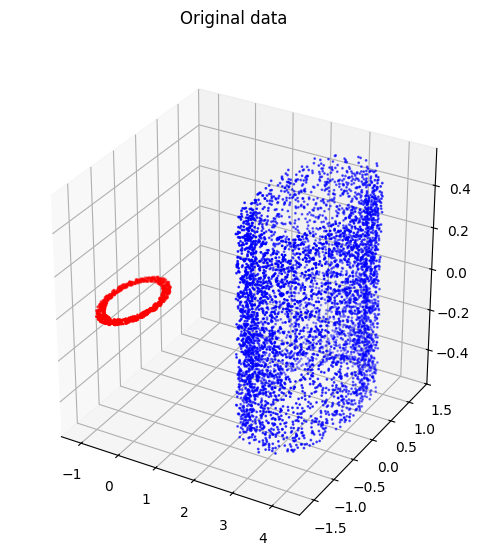

In [4]:

# show data

x0, x1 = make_fig1_data(seed=0)
# plot in 3d
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(*x0.T, c='r', s=1)
ax.scatter(*x1.T, c='b', s=1)
ax.set_box_aspect([1,1,1])  # Equal aspect ratio

fig.suptitle("Original data")
fig.savefig(os.path.join(fig_path, "fig1_data.png"))

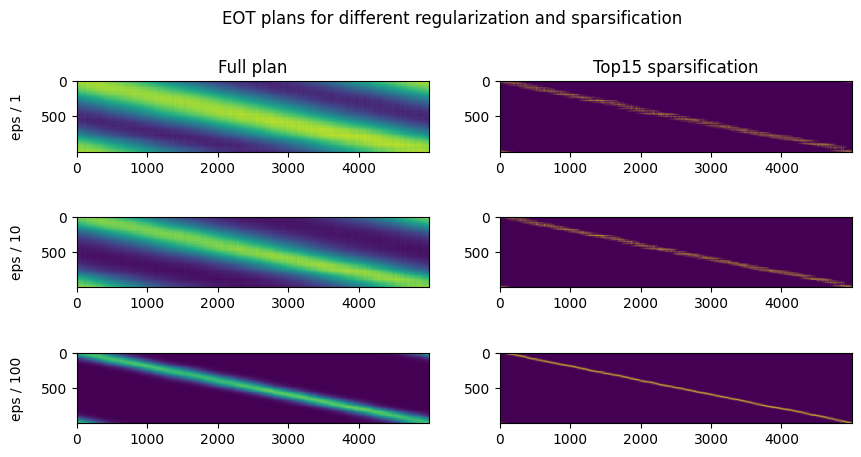

In [73]:
# show plans
sparsify = None # "topk" # None # "topk" # None

seed = 0
t=0
sparsity = "topk"

fig, ax = plt.subplots( len(eps_times_list), 2, figsize=(10, 5))

for i, eps_times in enumerate(eps_times_list):

    filename = os.path.join(res_path,
                            f"{dataset}_seed_{seed}_epstimes_{eps_times}_sparsify_{sparsify}_dim_{embd_dim}_EOT_t_{t}.npz")
    a = np.load(os.path.join(res_path, filename))
    P = a["P_sparse"]

    P_topk = sparsify_plan(P, mode=sparsity, k=15)

    ax[i, 0].imshow(P, interpolation="none")
    ax[i, 0].text(s=f"eps / {eps_times}", rotation="vertical", va="center", ha="right", x=-0.15, y=0.5, transform=ax[i, 0].transAxes)

    ax[i, 1].imshow(P_topk)

    if i == 0:
        ax[i, 0].set_title("Full plan")
        ax[i, 1].set_title("Top15 sparsification")

fig.suptitle("EOT plans for different regularization and sparsification")
fig.savefig(os.path.join(fig_path, "fig1_plans.png"))

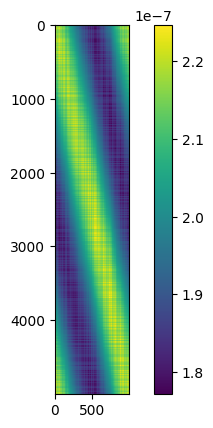

In [6]:
# colorbar is bad, plan with normal eps is non-sparse
eps_times = 1
sparsify = None # "topk" # None # "topk" # None

seed = 0
t=0
filename = os.path.join(res_path,
                            f"{dataset}_seed_{seed}_epstimes_{eps_times}_sparsify_{sparsify}_dim_{embd_dim}_EOT_t_{t}.npz")
a = np.load(os.path.join(res_path, filename))
P = a["P_sparse"]

plt.imshow(P.T, interpolation="none")
plt.colorbar()

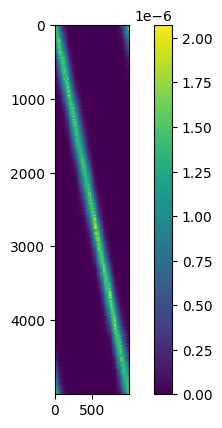

In [7]:
# plan with low eps is effectively sparse
eps_times = 100
sparsify = None # "topk" # None # "topk" # None

seed = 0
t=0
filename = os.path.join(res_path,
                            f"{dataset}_seed_{seed}_epstimes_{eps_times}_sparsify_{sparsify}_dim_{embd_dim}_EOT_t_{t}.npz")
a = np.load(os.path.join(res_path, filename))
P = a["P_sparse"]

plt.imshow(P.T, interpolation="none")
plt.colorbar()

In [74]:
# common hyperparams for NE runs
init_str = "random"  # "pca" or "random"
init_scale = 1

batch_size = 2**14
negative_samples = 5
n_epochs = 200
loss_mode = "infonce"

In [ ]:
## CNE experiemnts

In [75]:
# sample non-sparsified
alignment = True
sample_pos = "per_point"
sparsify = None



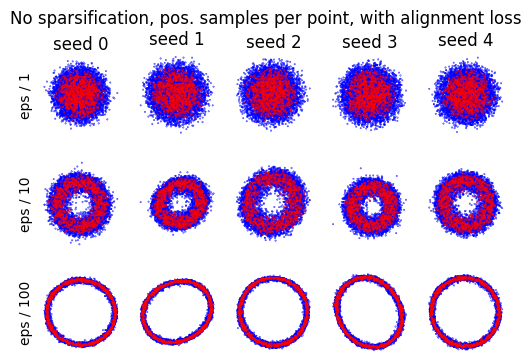

In [76]:

fig, ax = plt.subplots(len(eps_times_list),len(seeds), figsize=(6, 4))

for j, seed in enumerate(seeds):
    for i, eps_times in enumerate(eps_times_list):
        filename = os.path.join(res_path,
                            f"{dataset}_seed_{seed}_epstimes_{eps_times}_sparsify_{sparsify}_dim_{embd_dim}_init_{init_str}"+
                            f"_scale_{init_scale}_bs_{batch_size}_m_{negative_samples}_epochs_{n_epochs}"+
                            f"_loss_{loss_mode}_align_{alignment}_sample_pos_{sample_pos}.npz")
        a = np.load(os.path.join(res_path, filename))
        embd = a["embd"]
        plot_aligned_embedding(embd[::-1],
                               n0,
                               color =colors[::-1],
                               shuffle=False,
                               ax=ax[i, j],
                               s=0.1,
                               )
        if i == 0:
            ax[i, j].set_title(f"seed {seed}")
        if j == 0:
            ax[i, j].text(s=f"eps / {eps_times}", rotation="vertical", va="center", ha="right", x=-0.1, y=0.5, transform=ax[i, j].transAxes)

fig.suptitle("No sparsification, pos. samples per point, with alignment loss")
fig.savefig(os.path.join(fig_path, "fig1_per_point_sampling.png"))

In [79]:
for eps_times in eps_times_list:
    metrics_path = os.path.join(res_path,
                                f"{dataset}_epstimes_{eps_times}_sparsify_{sparsify}_dim_{embd_dim}_init_{init_str}"+
                                f"_scale_{init_scale}_bs_{batch_size}_m_{negative_samples}_epochs_{n_epochs}"+
                                f"_loss_{loss_mode}_align_{alignment}_sample_pos_{sample_pos}_metrics.npz")
    metrics = np.load(metrics_path)
    print(f"eps times: {eps_times}")
    print(f"Concordance: {metrics['concordance'].mean():.3f} ± {metrics['concordance'].std():.3f}")
    print(f"Cross concordance: {metrics['cross_concordance'].mean():.3f} ± {metrics['cross_concordance'].std():.3f}")
    print()

eps times: 1
Concordance: 0.015 ± 0.000
Cross concordance: 0.022 ± 0.000

eps times: 10
Concordance: 0.044 ± 0.001
Cross concordance: 0.191 ± 0.005

eps times: 100
Concordance: 0.136 ± 0.001
Cross concordance: 0.333 ± 0.010



In [80]:
# iterate over sparsified

alignment = True
sample_pos = None #"per_point"
sparsify = "topk"


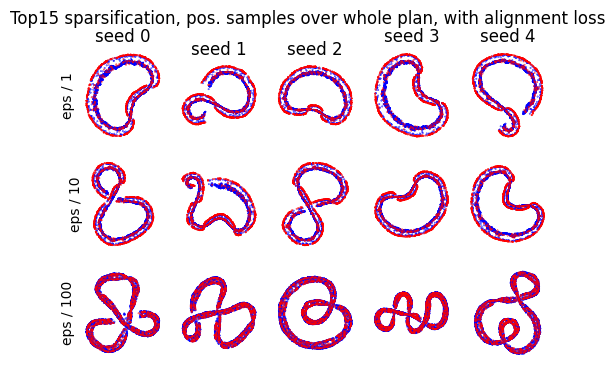

In [81]:
fig, ax = plt.subplots( len(eps_times_list), len(seeds), figsize=(6, 4))

for j, seed in enumerate(seeds):
    for i, eps_times in enumerate(eps_times_list):
        filename = os.path.join(res_path,
                            f"{dataset}_seed_{seed}_epstimes_{eps_times}_sparsify_{sparsify}_dim_{embd_dim}_init_{init_str}"+
                            f"_scale_{init_scale}_bs_{batch_size}_m_{negative_samples}_epochs_{n_epochs}"+
                            f"_loss_{loss_mode}_align_{alignment}_sample_pos_{sample_pos}.npz")
        a = np.load(os.path.join(res_path, filename))
        embd = a["embd"]
        plot_aligned_embedding(embd[::-1],
                               n0,
                               color =colors[::-1],
                               shuffle=False,
                               ax=ax[i, j],
                               s=0.1,
                               )
        if i == 0:
            ax[i, j].set_title(f"seed {seed}")
        if j == 0:
            ax[i, j].text(s=f"eps / {eps_times}", rotation="vertical", va="center", ha="right", x=-0.1, y=0.5, transform=ax[i, j].transAxes)

fig.suptitle("Top15 sparsification, pos. samples over whole plan, with alignment loss")
fig.savefig(os.path.join(fig_path, "fig1_topk_alignment.png"))


In [82]:
for eps_times in eps_times_list:
    metrics_path = os.path.join(res_path,
                                f"{dataset}_epstimes_{eps_times}_sparsify_{sparsify}_dim_{embd_dim}_init_{init_str}"+
                                f"_scale_{init_scale}_bs_{batch_size}_m_{negative_samples}_epochs_{n_epochs}"+
                                f"_loss_{loss_mode}_align_{alignment}_sample_pos_{sample_pos}_metrics.npz")
    metrics = np.load(metrics_path)
    print(f"eps times: {eps_times}")
    print(f"Concordance: {metrics['concordance'].mean():.3f} ± {metrics['concordance'].std():.3f}")
    print(f"Cross concordance: {metrics['cross_concordance'].mean():.3f} ± {metrics['cross_concordance'].std():.3f}")
    print()

eps times: 1
Concordance: 0.309 ± 0.002
Cross concordance: 0.418 ± 0.008

eps times: 10
Concordance: 0.305 ± 0.003
Cross concordance: 0.401 ± 0.006

eps times: 100
Concordance: 0.371 ± 0.006
Cross concordance: 0.336 ± 0.013



In [83]:
## no alignement loss
alignment = False
sample_pos = None #"per_point"
sparsify = "topk"


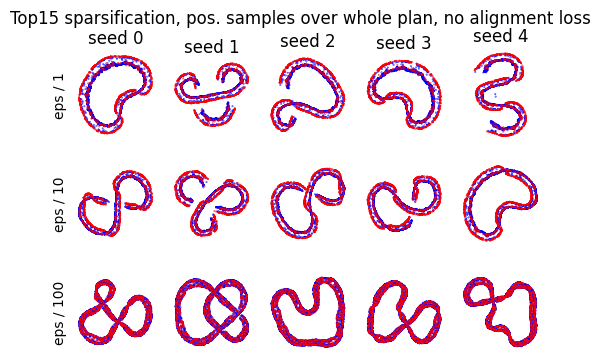

In [84]:
fig, ax = plt.subplots( len(eps_times_list), len(seeds), figsize=(6, 4))

for j, seed in enumerate(seeds):
    for i, eps_times in enumerate(eps_times_list):
        filename = os.path.join(res_path,
                            f"{dataset}_seed_{seed}_epstimes_{eps_times}_sparsify_{sparsify}_dim_{embd_dim}_init_{init_str}"+
                            f"_scale_{init_scale}_bs_{batch_size}_m_{negative_samples}_epochs_{n_epochs}"+
                            f"_loss_{loss_mode}_align_{alignment}_sample_pos_{sample_pos}.npz")
        a = np.load(os.path.join(res_path, filename))
        embd = a["embd"]
        plot_aligned_embedding(embd[::-1],
                               n0,
                               s=0.1,
                               color =colors[::-1],
                               shuffle=False,
                               ax=ax[i, j],
                               )
        if i == 0:
            ax[i, j].set_title(f"seed {seed}")
        if j == 0:
            ax[i, j].text(s=f"eps / {eps_times}", rotation="vertical", va="center", ha="right", x=-0.1, y=0.5, transform=ax[i, j].transAxes)
fig.suptitle("Top15 sparsification, pos. samples over whole plan, no alignment loss")
fig.savefig(os.path.join(fig_path, "fig1_topk_no_alignment.png"))


In [85]:
for eps_times in eps_times_list:
    metrics_path = os.path.join(res_path,
                                f"{dataset}_epstimes_{eps_times}_sparsify_{sparsify}_dim_{embd_dim}_init_{init_str}"+
                                f"_scale_{init_scale}_bs_{batch_size}_m_{negative_samples}_epochs_{n_epochs}"+
                                f"_loss_{loss_mode}_align_{alignment}_sample_pos_{sample_pos}_metrics.npz")
    metrics = np.load(metrics_path)
    print(f"eps times: {eps_times}")
    print(f"Concordance: {metrics['concordance'].mean():.3f} ± {metrics['concordance'].std():.3f}")
    print(f"Cross concordance: {metrics['cross_concordance'].mean():.3f} ± {metrics['cross_concordance'].std():.3f}")
    print()

eps times: 1
Concordance: 0.308 ± 0.001
Cross concordance: 0.416 ± 0.010

eps times: 10
Concordance: 0.304 ± 0.003
Cross concordance: 0.396 ± 0.006

eps times: 100
Concordance: 0.370 ± 0.006
Cross concordance: 0.338 ± 0.008



In [86]:
# EOT

In [87]:
sparsify = None # "topk" # None # "topk" # None


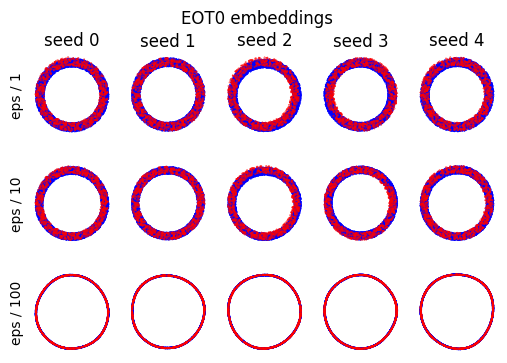

In [88]:
t=0

fig, ax = plt.subplots( len(eps_times_list), len(seeds), figsize=(6, 4))

for j, seed in enumerate(seeds):
    for i, eps_times in enumerate(eps_times_list):
        filename = os.path.join(res_path,
                            f"{dataset}_seed_{seed}_epstimes_{eps_times}_sparsify_{sparsify}_dim_{embd_dim}_EOT_t_{t}.npz")
        a = np.load(os.path.join(res_path, filename))
        embd = a["embd"]
        plot_aligned_embedding(embd[::-1],
                               n0,
                               s=0.1,
                               color =colors[::-1],
                               shuffle=False,
                               ax=ax[i, j],
                               )
        if i == 0:
            ax[i, j].set_title(f"seed {seed}")
        if j == 0:
            ax[i, j].text(s=f"eps / {eps_times}", rotation="vertical", va="center", ha="right", x=-0.1, y=0.5, transform=ax[i, j].transAxes)
fig.suptitle("EOT0 embeddings")
fig.savefig(os.path.join(fig_path, "fig1_EOT0.png"))

In [90]:
for eps_times in eps_times_list:
    metrics_path = os.path.join(res_path,
                                f"{dataset}_epstimes_{eps_times}_sparsify_{sparsify}_dim_{embd_dim}_EOT_t_{t}_metrics.npz")
    metrics = np.load(metrics_path)
    print(f"eps times: {eps_times}")
    print(f"Concordance: {metrics['concordance'].mean():.3f} ± {metrics['concordance'].std():.3f}")
    print(f"Cross concordance: {metrics['cross_concordance'].mean():.3f} ± {metrics['cross_concordance'].std():.3f}")
    print()

eps times: 1
Concordance: 0.624 ± 0.005
Cross concordance: 0.340 ± 0.004

eps times: 10
Concordance: 0.613 ± 0.002
Cross concordance: 0.341 ± 0.005

eps times: 100
Concordance: 0.248 ± 0.001
Cross concordance: 0.347 ± 0.010



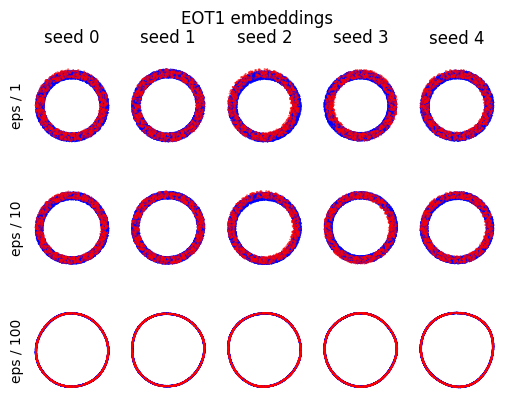

In [91]:
t=1

fig, ax = plt.subplots( len(eps_times_list), len(seeds), figsize=(6, 4.5))

for j, seed in enumerate(seeds):
    for i, eps_times in enumerate(eps_times_list):
        filename = os.path.join(res_path,
                            f"{dataset}_seed_{seed}_epstimes_{eps_times}_sparsify_{sparsify}_dim_{embd_dim}_EOT_t_{t}.npz")
        a = np.load(os.path.join(res_path, filename))
        embd = a["embd"]
        plot_aligned_embedding(embd[::-1],
                               n0,
                               s=0.1,
                               color =colors[::-1],
                               shuffle=False,
                               ax=ax[i, j],
                               )
        if i == 0:
            ax[i, j].set_title(f"seed {seed}")
        if j == 0:
            ax[i, j].text(s=f"eps / {eps_times}", rotation="vertical", va="center", ha="right", x=-0.1, y=0.5, transform=ax[i, j].transAxes)

fig.suptitle("EOT1 embeddings")
fig.savefig(os.path.join(fig_path, "fig1_EOT1.png"))

In [92]:
for eps_times in eps_times_list:
    metrics_path = os.path.join(res_path,
                                f"{dataset}_epstimes_{eps_times}_sparsify_{sparsify}_dim_{embd_dim}_EOT_t_{t}_metrics.npz")
    metrics = np.load(metrics_path)
    print(f"eps times: {eps_times}")
    print(f"Concordance: {metrics['concordance'].mean():.3f} ± {metrics['concordance'].std():.3f}")
    print(f"Cross concordance: {metrics['cross_concordance'].mean():.3f} ± {metrics['cross_concordance'].std():.3f}")
    print()

eps times: 1
Concordance: 0.624 ± 0.005
Cross concordance: 0.341 ± 0.004

eps times: 10
Concordance: 0.613 ± 0.002
Cross concordance: 0.342 ± 0.005

eps times: 100
Concordance: 0.248 ± 0.001
Cross concordance: 0.347 ± 0.010



In [ ]:
# t-SNE

In [93]:
# common hyperparams for NE runs
init_str = "random"  # "pca" or "random"
init_scale = 10000

n_epochs = 200
norm = "whole"

In [94]:
# sample topk
sparsify = "topk"

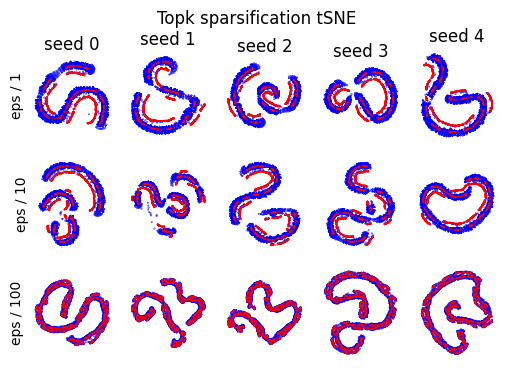

In [95]:

fig, ax = plt.subplots(len(eps_times_list),len(seeds), figsize=(6, 4))

for j, seed in enumerate(seeds):
    for i, eps_times in enumerate(eps_times_list):
        filename = os.path.join(res_path,
                            f"{dataset}_seed_{seed}_epstimes_{eps_times}_sparsify_{sparsify}_norm_{norm}_dim_{embd_dim}_init_{init_str}" + \
                                f"_scale_{init_scale}_epochs_{n_epochs}_tsne.npz")
        a = np.load(os.path.join(res_path, filename))
        embd = a["embd"]
        plot_aligned_embedding(embd[::-1],
                               n0,
                               color =colors[::-1],
                               shuffle=False,
                               ax=ax[i, j],
                               s=0.1,
                               )
        if i == 0:
            ax[i, j].set_title(f"seed {seed}")
        if j == 0:
            ax[i, j].text(s=f"eps / {eps_times}", rotation="vertical", va="center", ha="right", x=-0.1, y=0.5, transform=ax[i, j].transAxes)

fig.suptitle("Topk sparsification tSNE")
fig.savefig(os.path.join(fig_path, "fig1_topk_tsne.png"))

In [96]:
for eps_times in eps_times_list:
    metrics_path = os.path.join(res_path,
                                f"{dataset}_epstimes_{eps_times}_sparsify_{sparsify}_norm_{norm}_dim_{embd_dim}_init_{init_str}" + \
                                f"_scale_{init_scale}_epochs_{n_epochs}_tsne_metrics.npz")
    metrics = np.load(metrics_path)
    print(f"eps times: {eps_times}")
    print(f"Concordance: {metrics['concordance'].mean():.3f} ± {metrics['concordance'].std():.3f}")
    print(f"Cross concordance: {metrics['cross_concordance'].mean():.3f} ± {metrics['cross_concordance'].std():.3f}")
    print()

eps times: 1
Concordance: 0.267 ± 0.002
Cross concordance: 0.388 ± 0.004

eps times: 10
Concordance: 0.275 ± 0.005
Cross concordance: 0.386 ± 0.010

eps times: 100
Concordance: 0.375 ± 0.003
Cross concordance: 0.383 ± 0.009



In [97]:
# sample topk
sparsify = "weighted_topk"

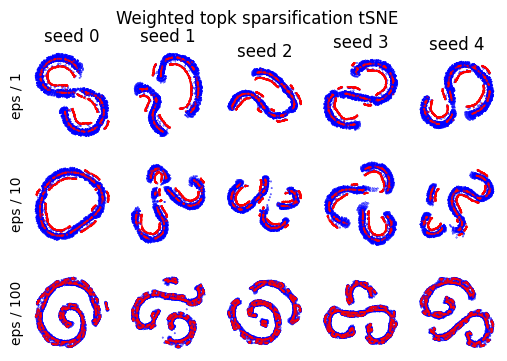

In [98]:

fig, ax = plt.subplots(len(eps_times_list),len(seeds), figsize=(6, 4))

for j, seed in enumerate(seeds):
    for i, eps_times in enumerate(eps_times_list):
        filename = os.path.join(res_path,
                            f"{dataset}_seed_{seed}_epstimes_{eps_times}_sparsify_{sparsify}_norm_{norm}_dim_{embd_dim}_init_{init_str}" + \
                                f"_scale_{init_scale}_epochs_{n_epochs}_tsne.npz")
        a = np.load(os.path.join(res_path, filename))
        embd = a["embd"]
        plot_aligned_embedding(embd[::-1],
                               n0,
                               color =colors[::-1],
                               shuffle=False,
                               ax=ax[i, j],
                               s=0.1,
                               )
        if i == 0:
            ax[i, j].set_title(f"seed {seed}")
        if j == 0:
            ax[i, j].text(s=f"eps / {eps_times}", rotation="vertical", va="center", ha="right", x=-0.1, y=0.5, transform=ax[i, j].transAxes)

fig.suptitle("Weighted topk sparsification tSNE")
fig.savefig(os.path.join(fig_path, "fig1_weighted_topk_tsne.png"))

In [99]:
for eps_times in eps_times_list:
    metrics_path = os.path.join(res_path,
                                f"{dataset}_epstimes_{eps_times}_sparsify_{sparsify}_norm_{norm}_dim_{embd_dim}_init_{init_str}" + \
                                f"_scale_{init_scale}_epochs_{n_epochs}_tsne_metrics.npz")
    metrics = np.load(metrics_path)
    print(f"eps times: {eps_times}")
    print(f"Concordance: {metrics['concordance'].mean():.3f} ± {metrics['concordance'].std():.3f}")
    print(f"Cross concordance: {metrics['cross_concordance'].mean():.3f} ± {metrics['cross_concordance'].std():.3f}")
    print()

eps times: 1
Concordance: 0.319 ± 0.005
Cross concordance: 0.398 ± 0.006

eps times: 10
Concordance: 0.367 ± 0.005
Cross concordance: 0.389 ± 0.014

eps times: 100
Concordance: 0.385 ± 0.004
Cross concordance: 0.388 ± 0.012



In [100]:
# sample None
sparsify = None

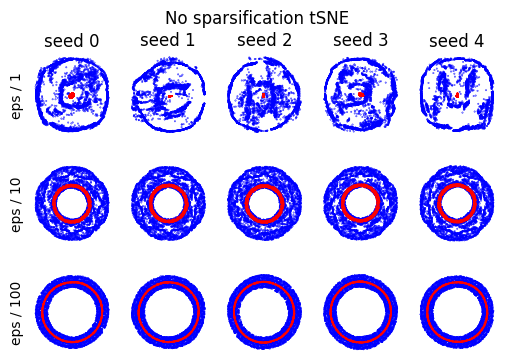

In [101]:

fig, ax = plt.subplots(len(eps_times_list),len(seeds), figsize=(6, 4))

for j, seed in enumerate(seeds):
    for i, eps_times in enumerate(eps_times_list):
        filename = os.path.join(res_path,
                            f"{dataset}_seed_{seed}_epstimes_{eps_times}_sparsify_{sparsify}_norm_{norm}_dim_{embd_dim}_init_{init_str}" + \
                                f"_scale_{init_scale}_epochs_{n_epochs}_tsne.npz")
        a = np.load(os.path.join(res_path, filename))
        embd = a["embd"]
        plot_aligned_embedding(embd[::-1],
                               n0,
                               color =colors[::-1],
                               shuffle=False,
                               ax=ax[i, j],
                               s=0.1,
                               )
        if i == 0:
            ax[i, j].set_title(f"seed {seed}")
        if j == 0:
            ax[i, j].text(s=f"eps / {eps_times}", rotation="vertical", va="center", ha="right", x=-0.1, y=0.5, transform=ax[i, j].transAxes)

fig.suptitle("No sparsification tSNE")
fig.savefig(os.path.join(fig_path, "fig1_non_sparse_tsne.png"))

In [103]:
for eps_times in eps_times_list:
    metrics_path = os.path.join(res_path,
                                f"{dataset}_epstimes_{eps_times}_sparsify_{sparsify}_norm_{norm}_dim_{embd_dim}_init_{init_str}" + \
                                f"_scale_{init_scale}_epochs_{n_epochs}_tsne_metrics.npz")
    metrics = np.load(metrics_path)
    print(f"eps times: {eps_times}")
    print(f"Concordance: {metrics['concordance'].mean():.3f} ± {metrics['concordance'].std():.3f}")
    print(f"Cross concordance: {metrics['cross_concordance'].mean():.3f} ± {metrics['cross_concordance'].std():.3f}")
    print()

eps times: 1
Concordance: 0.125 ± 0.037
Cross concordance: 0.133 ± 0.047

eps times: 10
Concordance: 0.350 ± 0.004
Cross concordance: 0.529 ± 0.004

eps times: 100
Concordance: 0.381 ± 0.002
Cross concordance: 0.335 ± 0.008



In [104]:
## norm per point

In [105]:
# common hyperparams for NE runs
init_str = "random"  # "pca" or "random"
init_scale = 10000

n_epochs = 200
norm = "per_point"

In [106]:
# sample topk
sparsify = "topk"

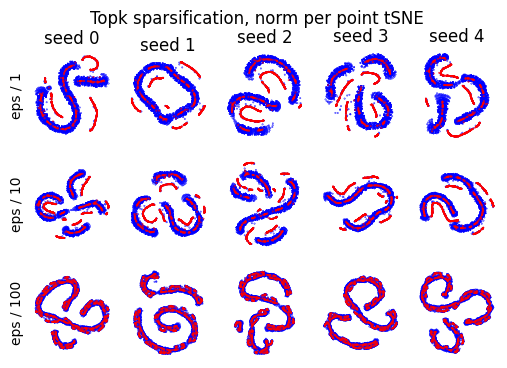

In [107]:

fig, ax = plt.subplots(len(eps_times_list),len(seeds), figsize=(6, 4))

for j, seed in enumerate(seeds):
    for i, eps_times in enumerate(eps_times_list):
        filename = os.path.join(res_path,
                            f"{dataset}_seed_{seed}_epstimes_{eps_times}_sparsify_{sparsify}_norm_{norm}_dim_{embd_dim}_init_{init_str}" + \
                                f"_scale_{init_scale}_epochs_{n_epochs}_tsne.npz")
        a = np.load(os.path.join(res_path, filename))
        embd = a["embd"]
        plot_aligned_embedding(embd[::-1],
                               n0,
                               color =colors[::-1],
                               shuffle=False,
                               ax=ax[i, j],
                               s=0.1,
                               )
        if i == 0:
            ax[i, j].set_title(f"seed {seed}")
        if j == 0:
            ax[i, j].text(s=f"eps / {eps_times}", rotation="vertical", va="center", ha="right", x=-0.1, y=0.5, transform=ax[i, j].transAxes)

fig.suptitle("Topk sparsification, norm per point tSNE")
fig.savefig(os.path.join(fig_path, "fig1_topk_per_point_tsne.png"))

In [108]:
for eps_times in eps_times_list:
    metrics_path = os.path.join(res_path,
                                f"{dataset}_epstimes_{eps_times}_sparsify_{sparsify}_norm_{norm}_dim_{embd_dim}_init_{init_str}" + \
                                f"_scale_{init_scale}_epochs_{n_epochs}_tsne_metrics.npz")
    metrics = np.load(metrics_path)
    print(f"eps times: {eps_times}")
    print(f"Concordance: {metrics['concordance'].mean():.3f} ± {metrics['concordance'].std():.3f}")
    print(f"Cross concordance: {metrics['cross_concordance'].mean():.3f} ± {metrics['cross_concordance'].std():.3f}")
    print()

eps times: 1
Concordance: 0.260 ± 0.003
Cross concordance: 0.326 ± 0.024

eps times: 10
Concordance: 0.269 ± 0.002
Cross concordance: 0.388 ± 0.005

eps times: 100
Concordance: 0.368 ± 0.004
Cross concordance: 0.374 ± 0.010



In [110]:
# sample None
sparsify = None

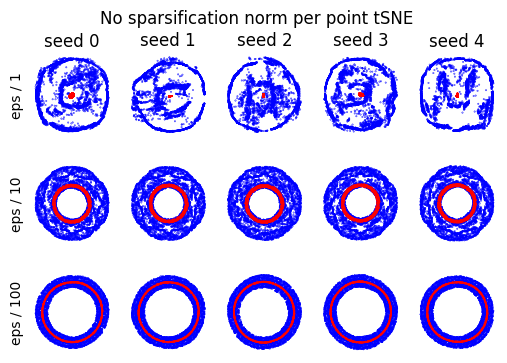

In [111]:

fig, ax = plt.subplots(len(eps_times_list),len(seeds), figsize=(6, 4))

for j, seed in enumerate(seeds):
    for i, eps_times in enumerate(eps_times_list):
        filename = os.path.join(res_path,
                            f"{dataset}_seed_{seed}_epstimes_{eps_times}_sparsify_{sparsify}_norm_{norm}_dim_{embd_dim}_init_{init_str}" + \
                                f"_scale_{init_scale}_epochs_{n_epochs}_tsne.npz")
        a = np.load(os.path.join(res_path, filename))
        embd = a["embd"]
        plot_aligned_embedding(embd[::-1],
                               n0,
                               color =colors[::-1],
                               shuffle=False,
                               ax=ax[i, j],
                               s=0.1,
                               )
        if i == 0:
            ax[i, j].set_title(f"seed {seed}")
        if j == 0:
            ax[i, j].text(s=f"eps / {eps_times}", rotation="vertical", va="center", ha="right", x=-0.1, y=0.5, transform=ax[i, j].transAxes)

fig.suptitle("No sparsification norm per point tSNE")
fig.savefig(os.path.join(fig_path, "fig1_non_sparse_per_point_tsne.png"))

In [114]:
for eps_times in eps_times_list:
    metrics_path = os.path.join(res_path,
                                f"{dataset}_epstimes_{eps_times}_sparsify_{sparsify}_norm_{norm}_dim_{embd_dim}_init_{init_str}" + \
                                f"_scale_{init_scale}_epochs_{n_epochs}_tsne_metrics.npz")
    metrics = np.load(metrics_path)
    print(f"eps times: {eps_times}")
    print(f"Concordance: {metrics['concordance'].mean():.3f} ± {metrics['concordance'].std():.3f}")
    print(f"Cross concordance: {metrics['cross_concordance'].mean():.3f} ± {metrics['cross_concordance'].std():.3f}")
    print()

eps times: 1
Concordance: 0.125 ± 0.037
Cross concordance: 0.133 ± 0.047

eps times: 10
Concordance: 0.350 ± 0.004
Cross concordance: 0.529 ± 0.004

eps times: 100
Concordance: 0.381 ± 0.002
Cross concordance: 0.335 ± 0.008



In [183]:
## check out parallel lines

# iterate over sparsified

alignment = True
sample_pos = None  #"per_point"
sparsify = "topk"

init_scale = 1

seed = 1
eps_times = 1
filename = os.path.join(res_path,
                        f"{dataset}_seed_{seed}_epstimes_{eps_times}_sparsify_{sparsify}_dim_{embd_dim}_init_{init_str}" +
                        f"_scale_{init_scale}_bs_{batch_size}_m_{negative_samples}_epochs_{n_epochs}" +
                        f"_loss_{loss_mode}_align_{alignment}_sample_pos_{sample_pos}.npz")
a = np.load(os.path.join(res_path, filename))
embd = a["embd"]
P_sparse = a["P_sparse"]


In [ ]:
data0, data1 = make_fig1_data(seed=seed)


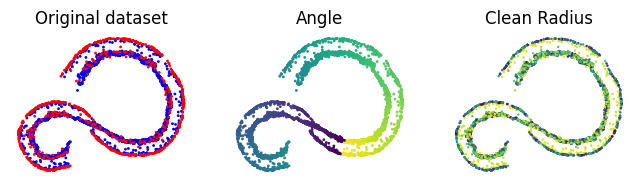

In [261]:
colors =  ["r"]*n0 + ["b"]*n1

fig, ax = plt.subplots(1, 3, figsize=(8, 5))

plot_aligned_embedding(embd[::-1],
                       n0,
                       color=colors[::-1],
                       shuffle=False,
                       ax=ax[0],
                       s=1,
                       )
ax[0].set_title("Original dataset")


cmap = plt.get_cmap("viridis")
colors_angle = [cmap(i / n0) for i in range(n0)] + [cmap(i / n1) for i in range(n1)]

plot_aligned_embedding(embd[::-1],
                       n0,
                       color=colors_angle[::-1],
                       shuffle=False,
                       ax=ax[1],
                       s=1,
                       )

ax[1].set_title("Angle")

clean0, clean1 = make_fig1_data(seed=seed, clean=True)

clean = np.concatenate((clean0, clean1))

radii = np.sqrt(np.sum(clean ** 2, axis=1))
radii -= radii.min()
radii /= radii.max()
color_radius = [cmap(r) for r in radii]

plot_aligned_embedding(embd[::-1],
                       n0,
                       color=color_radius[::-1],
                       shuffle=False,
                       ax=ax[2],
                       s=0.5,
                       )

ax[2].set_title("Clean Radius")

fig.savefig(os.path.join(fig_path, "fig1_parallel_line.png"), dpi=300)

In [150]:
from sklearn.neighbors import NearestNeighbors

In [151]:
nbrs = NearestNeighbors(n_neighbors=15, algorithm='ball_tree').fit(embd)

_, idx = nbrs.kneighbors(embd)


In [155]:
mask0 = (idx[:n0] >= n0).sum(1) > 15/2
mask1 = (idx[n0:] <= n0).sum(1) > 15/2

In [156]:
mask0

array([False,  True,  True, False, False, False,  True, False, False,
       False,  True, False, False, False, False,  True, False,  True,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False,  True, False, False, False, False,
       False, False, False,  True, False, False, False, False, False,
       False,  True, False, False,  True, False,  True, False,  True,
        True,  True, False, False, False, False,  True, False, False,
       False,  True, False, False, False,  True, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False,  True,
        True,  True, False, False,  True, False, False,  True,  True,
        True,  True, False, False,  True,  True,  True, False, False,
       False, False, False,  True,  True, False, False, False,  True,
       False, False,  True, False, False, False,  True, False, False,
       False, False,

In [162]:
cmap = plt.get_cmap("viridis")
color_outliers0 = [cmap(i) for i in mask0]

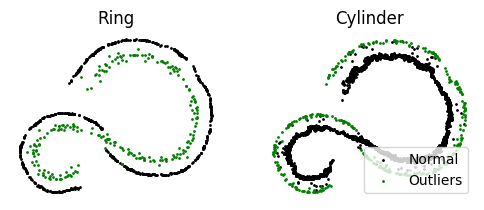

In [246]:

fig, ax = plt.subplots(1, 2, figsize=(6, 4))


ax[0].scatter(*embd[:n0][~mask0].T, s=1, c="k")
ax[0].scatter(*embd[:n0][mask0].T, s=1,c="g")
ax[0].set_aspect("equal")
ax[0].axis("off")
ax[0].set_title("Ring")

ax[1].scatter(*embd[n0:][~mask1].T, s=1, c="k", label="Normal")
ax[1].scatter(*embd[n0:][mask1].T, s=1,c="g", label="Outliers")
ax[1].set_aspect("equal")
ax[1].axis("off")
ax[1].set_title("Cylinder")

ax[1].legend(loc="lower right")
fig.savefig(os.path.join(fig_path, "outlier_locations.png"), dpi=300)

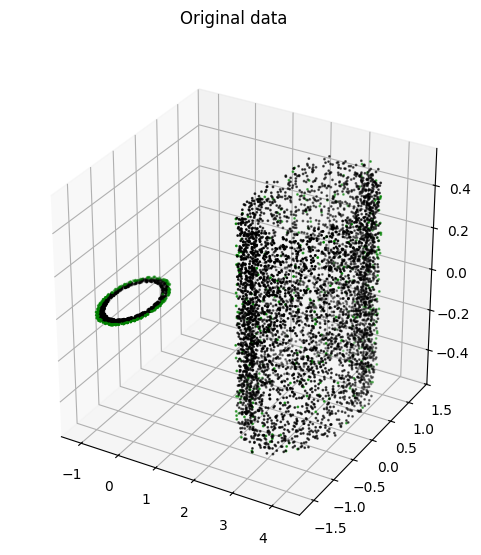

In [178]:
# show data

x0, x1 = make_fig1_data(seed=seed)
# plot in 3d
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(*x0[~mask0].T, c='k', s=1)
ax.scatter(*x0[mask0].T, c='g', s=1)
ax.scatter(*x1[~mask1].T, c='k', s=1)
ax.scatter(*x1[mask1].T, c='g', s=1)
ax.set_box_aspect([1,1,1])  # Equal aspect ratio

fig.suptitle("Original data")
fig.savefig(os.path.join(fig_path, "fig1_data_odd.png"))

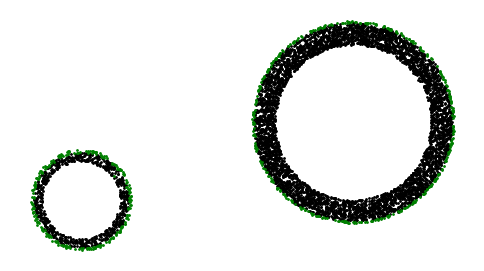

In [243]:
# show data

x0, x1 = make_fig1_data(seed=seed)
x0 = x0[:, :2]
x1 = x1[:, :2]
# plot in 3d
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(*x0[~mask0].T, c='k', s=1)
ax.scatter(*x0[mask0].T, c='g', s=1)
ax.scatter(*x1[~mask1].T, c='k', s=1)
ax.scatter(*x1[mask1].T, c='g', s=1)
ax.set_aspect("equal")
ax.axis("off")
fig.savefig(os.path.join(fig_path, "fig1_data_odd_top.png"))

In [187]:
mass0 = P_sparse.sum(1)
mass1 = P_sparse.sum(0)

{'whiskers': [<matplotlib.lines.Line2D at 0x7f344b7178f0>,
 'caps': [<matplotlib.lines.Line2D at 0x7f344b717ec0>,
 'boxes': [<matplotlib.lines.Line2D at 0x7f344b717620>,
 'medians': [<matplotlib.lines.Line2D at 0x7f344b7444d0>,
 'fliers': [<matplotlib.lines.Line2D at 0x7f344b7447a0>,
 'means': []}

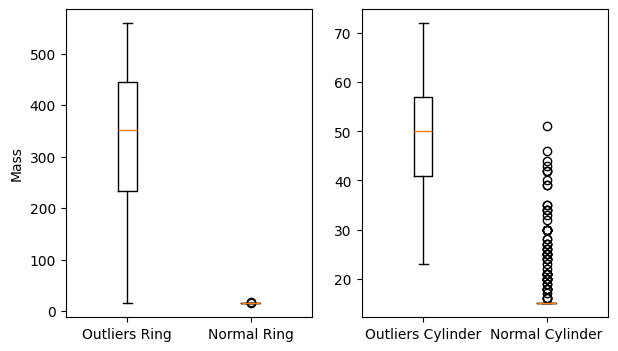

In [204]:
fig, ax = plt.subplots(1, 2, figsize=(7, 4))


ax[0].boxplot([mass0[mask0], mass0[~mask0]], tick_labels=["Outliers Ring", "Normal Ring"])
ax[0].set_ylabel("Mass")

ax[1].boxplot([mass1[mask1], mass1[~mask1]], tick_labels=["Outliers Cylinder", "Normal Cylinder"])

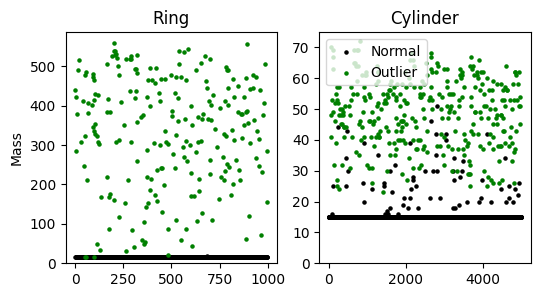

In [241]:
fig, ax = plt.subplots(1, 2, figsize=(6, 3))
ax[0].scatter(np.arange(n0)[~mask0], mass0[~mask0], s=5, c="k")
ax[0].scatter(np.arange(n0)[mask0],  mass0[mask0],  s=5, c="g")
ax[0].set_ylim(0, None)
ax[0].set_ylabel("Mass")
ax[0].set_title("Ring")

ax[1].scatter(np.arange(n1)[~mask1], mass1[~mask1],label="Normal", s=5, c="k")
ax[1].scatter(np.arange(n1)[mask1],  mass1[mask1], label="Outlier", s=5, c="g")
ax[1].set_ylim(0, None)
ax[1].legend()
ax[1].set_title("Cylinder")

fig.savefig(os.path.join(fig_path, "outlier_mass.png"), dpi=300)

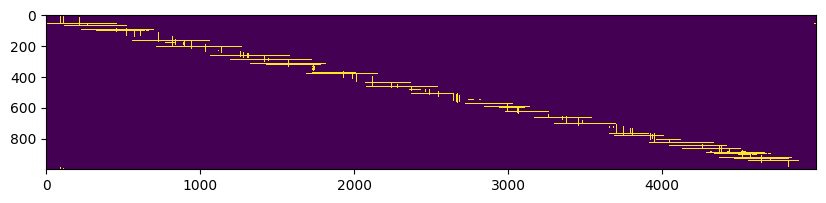

In [266]:
fig, ax = plt.subplots(figsize=(10, 2))
ax.imshow(P_sparse, interpolation="none")
fig.savefig(os.path.join(fig_path, "fig1_eps1_topk.png"), dpi=600)